# 01 · Análise exploratória e entendimento do problema

**Pergunta:** quais municípios têm risco de **não atingir a meta** de alfabetização, e por quê?

A EDA apoia diretamente as decisões de modelagem: cada achado abaixo termina com a decisão que ele motiva.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.config import *
from src.preprocessing.build_dataset import carrega_gold, constroi, colunas_features
from src.visualization import plots
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

## 1. A Gold da Fase 2: cobertura e qualidade

In [2]:
ind, mv = carrega_gold()
print("indicador:", ind.shape, "| meta_vs_resultado:", mv.shape)
cob = mv.groupby("ano").agg(municipios=("id_municipio", "nunique"),
                            meta_nula=("meta_percentual", lambda s: s.isna().mean()),
                            atingiu_meta_True=("atingiu_meta", "sum"))
display(cob)

indicador: (10392, 7) | meta_vs_resultado: (10392, 8)


,municipios,meta_nula,atingiu_meta_True
ano,,,
2023,4873,1.000000,0
2024,5519,0.052002,2820


**Achado 1 – bug herdado da Fase 2.** Em 2023 não existe meta (100% nula), mas `atingiu_meta` aparece como `False` para todos os municípios, porque `NaN >= 0` é falso. Esse rótulo é inválido.

**Decisão:** o alvo só é definido onde há meta *e* resultado (2024). Linhas sem meta são descartadas, não rotuladas como fracasso.

ano                               2023     2024
percentual_alfabetizado count  4871.00  5517.00
                        mean     60.51    63.16
                        std      20.11    19.02
                        min       4.56     0.00
                        25%      45.96    48.98
                        50%      61.46    64.29
                        75%      75.75    77.75
                        max     100.00   100.00
proficiencia_media      count  4871.00  5517.00
                        mean    750.81   753.37
                        std      24.10    22.19
                        min     673.28   685.03
                        25%     735.22   738.45
                        50%     750.22   752.41
                        75%     763.98   765.58
                        max     868.22   868.01

nulos: {'id_municipio': 0, 'nome_municipio': 0, 'sigla_uf': 0, 'nome_uf': 0, 'ano': 0, 'proficiencia_media': 4, 'percentual_alfabetizado': 4}


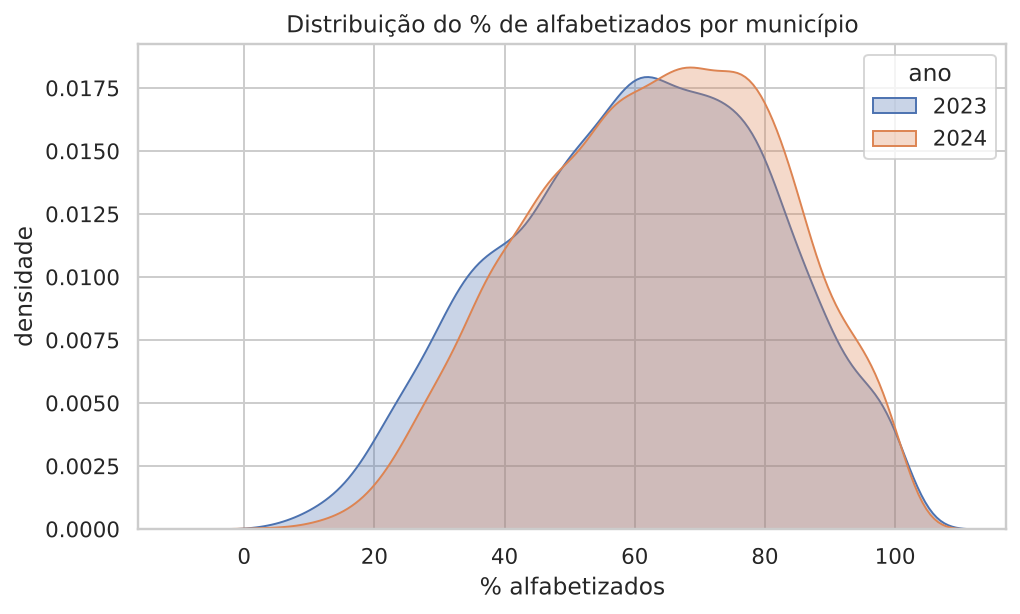

In [3]:
t = ind.groupby("ano")[["percentual_alfabetizado", "proficiencia_media"]].describe().T
display(t.round(2))
print("nulos:", ind.isna().sum().to_dict())
display(Image(plots.distribuicao_alfabetizacao(ind)))

## 2. Construção do alvo (sem leakage)

Desenho temporal: **desempenho de 2023 + contexto → atingiu a meta em 2024?**  
O `percentual_alfabetizado` e a proficiência de 2024 definem o alvo, então ficam **fora** das features. A **meta de 2024** também fica fora: ela é o limiar do alvo e carrega a política de metas de cada estado (ver notebook 02).

In [4]:
df, usadas = constroi()
print(df.shape, "| fontes externas:", usadas or "nenhuma ainda")
print("taxa de risco (não atingiu):", round(df[TARGET].mean(), 3))
print("municípios sem histórico em 2023:", int(df["pct_ant"].isna().sum()))
print("features candidatas:", colunas_features(df))

(5232, 77) | fontes externas: ['ibge_territorio', 'ibge_pib', 'inep_censo_escolar', 'inep_alunos_avaliados', 'inep_ideb', 'atlas_idhm', 'fundeb', 'diretorio_municipios']
taxa de risco (não atingiu): 0.461
municípios sem histórico em 2023: 621
features candidatas: ['prof_ant', 'pct_ant', 'ext_ibge_territorio__area_da_unidade_territorial', 'ext_ibge_territorio__densidade_demografica', 'ext_ibge_territorio__populacao_residente', 'ext_ibge_pib__pib_mil_reais', 'ext_inep_censo_escolar__qtd_escolas', 'ext_inep_censo_escolar__pct_banda_larga', 'ext_inep_censo_escolar__pct_equipamento_computador', 'ext_inep_censo_escolar__pct_equipamento_tv', 'ext_inep_censo_escolar__pct_equipamento_copiadora', 'ext_inep_censo_escolar__pct_equipamento_impressora', 'ext_inep_censo_escolar__pct_internet', 'ext_inep_censo_escolar__pct_biblioteca', 'ext_inep_censo_escolar__pct_laboratorio_informatica', 'ext_inep_censo_escolar__pct_quadra_esportes', 'ext_inep_alunos_avaliados__qtd_alunos_avaliados', 'ext_inep_ideb_

**Achado 2 – classes equilibradas** (≈46% em risco): acurácia não engana, mas reportamos F1, ROC-AUC e PR-AUC com foco no recall da classe de risco.  
**Achado 3 – 621 municípios sem histórico:** imputação com mediana **mais um indicador de ausência**, dentro do Pipeline.

## 3. Território e contexto socioeconômico

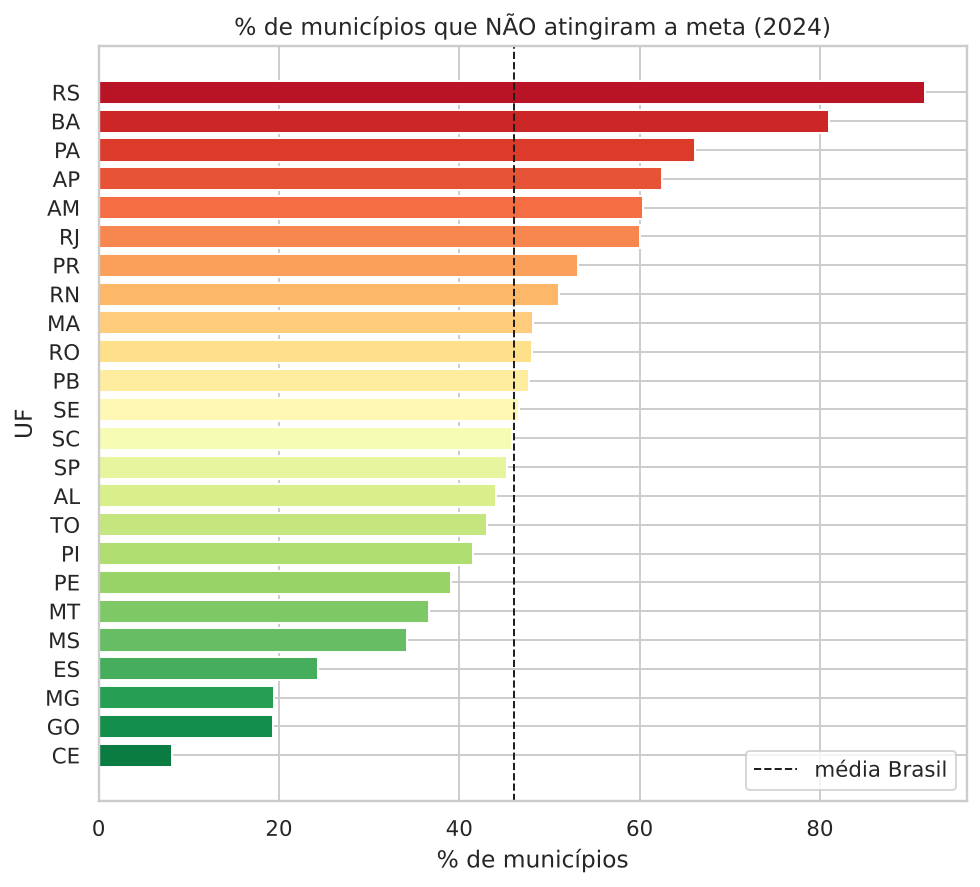

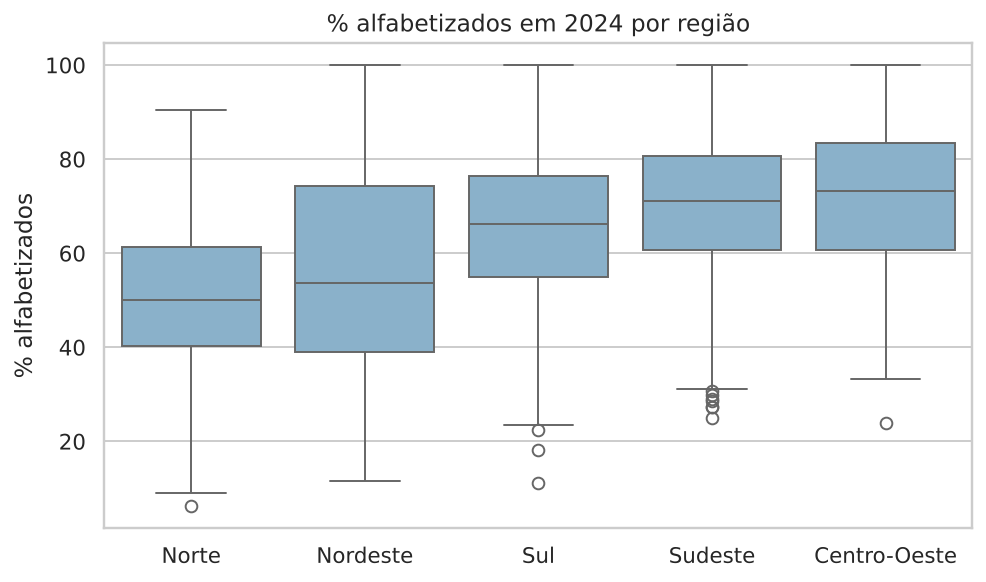

,risco_nao_atingir_meta,pct_alvo,meta_alvo
regiao,,,
Centro-Oeste,0.271,72.199,65.625
Nordeste,0.494,56.884,55.672
Norte,0.548,50.717,50.955
Sudeste,0.321,70.378,64.231
Sul,0.669,65.055,72.313


In [5]:
display(Image(plots.risco_por_uf(df)))
display(Image(plots.alfabetizacao_por_regiao(df)))
display(df.groupby("regiao")[[TARGET, "pct_alvo", "meta_alvo"]].mean().round(3))

**Achado 4 – a taxa de risco varia de ~8% (CE) a ~92% (RS) entre UFs.** Parte disso vem de **como as metas foram fixadas por estado**, não só do desempenho.  
**Decisões:** (i) **UF e região não entram no modelo**: queremos que ele aprenda com características do município, não com a identidade do estado; (ii) `sigla_uf` fica no dataset apenas para a validação por grupo (`GroupKFold`), que mede a generalização a estados não vistos; (iii) fontes em nível estadual (PNAD/UF) também ficam de fora, porque identificariam a UF indiretamente.

## 4. Fontes externas: o que elas dizem sobre o desempenho e sobre o risco

In [6]:
ext = [c for c in df.columns if c.startswith("ext_")]
print(len(ext), "variáveis externas |", usadas)
print("nulos (maiores):"); display(df[ext].isna().mean().sort_values(ascending=False).head(5).round(3))
c_nivel = df[ext].corrwith(df["pct_alvo"]).sort_values(key=abs, ascending=False).head(10)
c_risco = df[ext].corrwith(df[TARGET]).sort_values(key=abs, ascending=False).head(10)
display(pd.concat({"corr com % alfabetizados 2024": c_nivel.reset_index(drop=True).to_frame().assign(variavel=c_nivel.index),
                   "corr com risco": c_risco.reset_index(drop=True).to_frame().assign(variavel=c_risco.index)}, axis=1).round(3))

66 variáveis externas | ['ibge_territorio', 'ibge_pib', 'inep_censo_escolar', 'inep_alunos_avaliados', 'inep_ideb', 'atlas_idhm', 'fundeb', 'diretorio_municipios']
nulos (maiores):


ext_inep_alunos_avaliados__qtd_alunos_avaliados    0.119
ext_inep_ideb__projecao                            0.003
ext_inep_ideb__ideb                                0.002
ext_inep_ideb__nota_saeb_media_padronizada         0.002
ext_inep_ideb__nota_saeb_lingua_portuguesa         0.002
dtype: float64

corr com % alfabetizados 2024                                             corr com risco                                            
                              0                                    variavel              0                                    variavel
0                         0.579                         ext_inep_ideb__ideb         -0.182               ext_inep_ideb__taxa_aprovacao
1                         0.549  ext_inep_ideb__nota_saeb_media_padronizada         -0.182         ext_inep_ideb__indicador_rendimento
2                         0.545         ext_inep_ideb__nota_saeb_matematica         -0.180                         ext_inep_ideb__ideb
3                         0.541  ext_inep_ideb__nota_saeb_lingua_portuguesa         -0.159         ext_inep_ideb__nota_saeb_matematica
4                         0.432               ext_inep_ideb__taxa_aprovacao         -0.158  ext_inep_ideb__nota_saeb_media_padronizada
5                         0.430         ext_inep_ideb__indicador_rendimento         -0.153  ext_inep_ideb__nota_saeb_lingua_portuguesa
6                         0.345                     ext_inep_ideb__projecao         -0.107  ext_atlas_idhm__taxa_ocupados_sem_carteira
7                         0.337   ext_atlas_idhm__indice_frequencia_escolar         -0.085               ext_atlas_idhm__taxa_freq_5_6
8                         0.310   ext_atlas_idhm__taxa_atraso_0_fundamental         -0.076         ext_atlas_idhm__taxa_freq_bruta_pre
9                        -0.298       ext_atlas_idhm__taxa_densidade_2_mais         -0.075                     ext_inep_ideb__projecao

**Achado 5 – contexto explica o NÍVEL, mas quase não explica o RISCO.** As variáveis do IDEB/SAEB (r≈0,55–0,58), frequência escolar, atraso escolar e densidade domiciliar correlacionam com o percentual de alfabetizados; já com o risco de não atingir a meta a correlação máxima é ≈0,18. Isso acontece porque **as metas já são calibradas pelo ponto de partida do município**: um município pobre tem meta menor.  
**Decisão:** além do modelo de risco, criamos um **modelo do nível de alfabetização** (`src/modeling/factors.py`) para responder à pergunta "quais fatores mais impactam a alfabetização?". Atenção: notas do SAEB são outro indicador de aprendizagem, então há uma variante **sem IDEB/SAEB** para isolar fatores de contexto.

## 5. Relação entre anos e metas

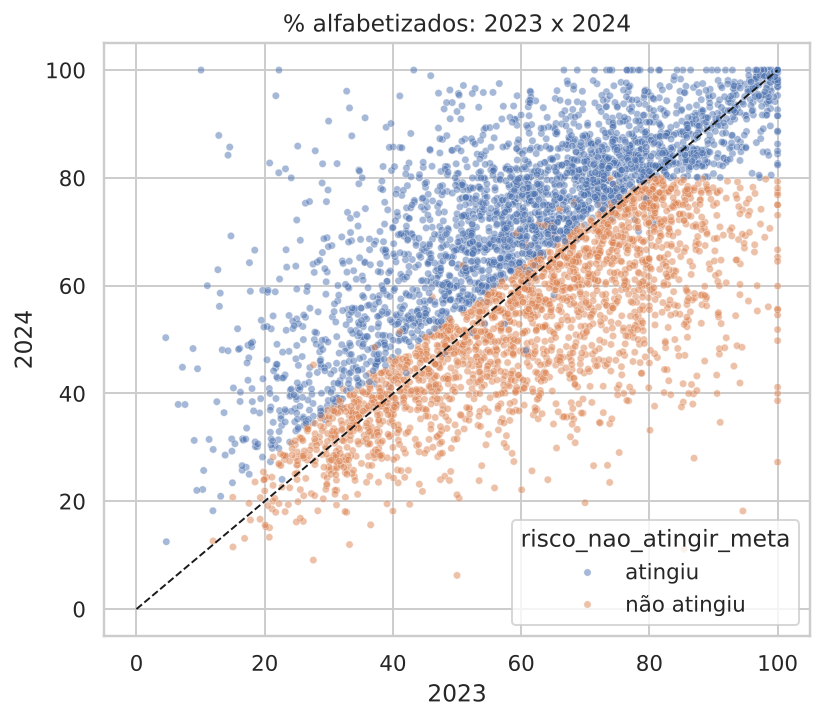

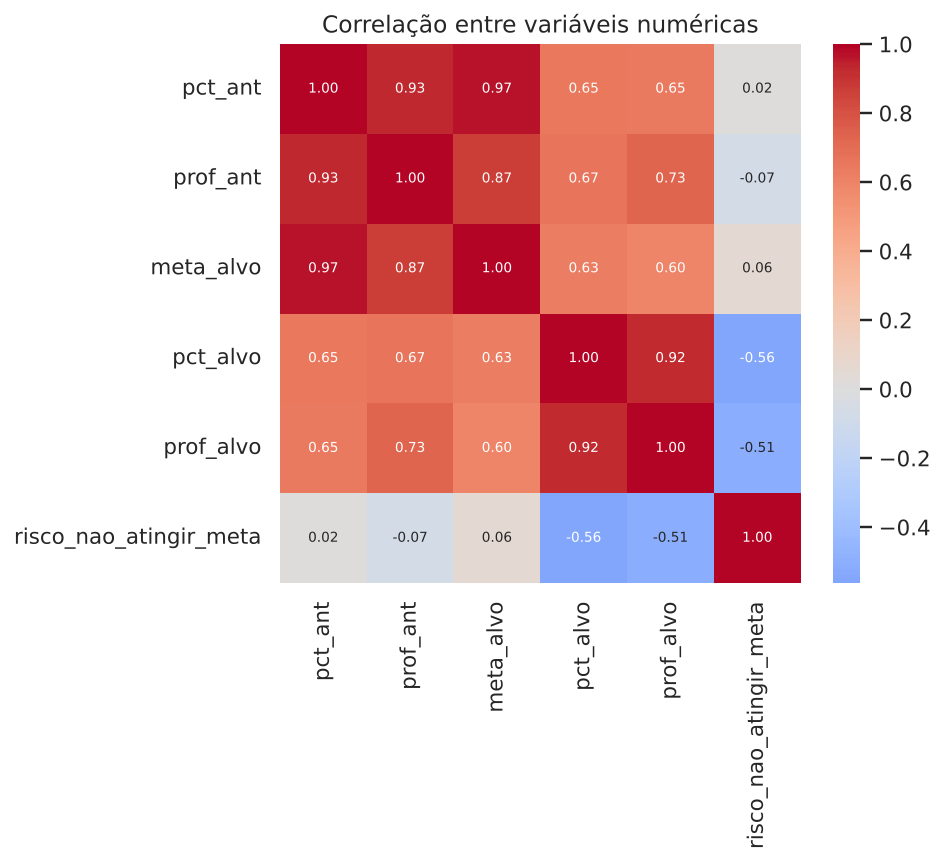

pct_ant                   0.017
prof_ant                 -0.073
meta_alvo                 0.058
pct_alvo                 -0.562
prof_alvo                -0.509
risco_nao_atingir_meta    1.000
Name: risco_nao_atingir_meta, dtype: float64

In [7]:
display(Image(plots.relacao_ant_alvo(df)))
num = ["pct_ant", "prof_ant", "meta_alvo", "pct_alvo", "prof_alvo", TARGET]
display(Image(plots.correlacoes(df, num)))
display(df[num].corr()[TARGET].round(3))

**Achado 6 – o desempenho passado é preditivo, mas não decide tudo:** a correlação 2023↔2024 é ≈0,65.  
**Hipóteses testadas:**
1. **H1** (gap negativo → mais risco): apoio parcial, ver tabela abaixo.
2. **H2** (UF tem poder próprio): confirmada na primeira versão; **a UF foi removida de propósito** e o modelo perde generalização entre estados (ver notebook 02).
3. **H3** (sem histórico se comporta diferente): **não se confirmou** (45,2% vs 46,2%).
4. **H4** (contexto socioeconômico explica o risco além do desempenho): **apoio parcial**: NSE do FUNDEB e pobreza extrema aparecem entre as 5 variáveis mais importantes, mas depois de `meta_alvo` e `prof_ant`.

In [8]:
df["gap_ant"] = df["pct_ant"] - df["meta_alvo"]
df["faixa_gap"] = pd.cut(df["gap_ant"], [-100, -20, -10, 0, 10, 100])
display(df.groupby("faixa_gap")[TARGET].agg(["mean", "count"]).round(3))   # H1
display(df.groupby(df["pct_ant"].isna())[TARGET].agg(["mean", "count"]).round(3))  # H3

,mean,count
faixa_gap,,
"(-100, -20]",0.600,10
"(-20, -10]",0.564,39
"(-10, 0]",0.468,3506
"(0, 10]",0.506,711
"(10, 100]",0.296,345


,mean,count
pct_ant,,
False,0.462,4611
True,0.452,621
